# EDA Superstore Sales — Exploratory Data Analysis

**Dataset**: Superstore Sales Forecasting (Kaggle: `rohitsahoo/sales-forecasting`)

1. Penyiapan dataset otomatis via `kagglehub` (pakai file lokal bila tersedia)
2. Parsing tanggal + fitur turunan (tahun, bulan, kuartal, lama kirim)
3. Cek kualitas data (missing value, duplikat, outlier)
4. Statistik deskriptif numerik & kategorikal
5. Visualisasi lengkap (distribusi, kategori, geografi, pelanggan, produk, time series, heatmap bulan × tahun, pengiriman)
6. Tabel agregat (CSV) tersimpan di folder `eda_output/`

## 1. Setup & Konfigurasi

Import library, konstanta, palet warna, serta helper `save_fig()` untuk menyimpan grafik ke `eda_output/` sekaligus menampilkannya secara inline di notebook.

In [1]:
import os
import shutil

import kagglehub
import numpy as np
import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

## Konfigurasi
CSV_NAME = "train.csv"
KAGGLE_DATASET = "rohitsahoo/sales-forecasting"
# Folder root project = induk dari folder ipynb/ (lokasi train.csv & eda_output/)
BASE_DIR = os.path.abspath(os.path.join(os.getcwd(), ".."))
if not os.path.isfile(os.path.join(BASE_DIR, CSV_NAME)):
    # fallback bila kernel dijalankan dari folder root project
    BASE_DIR = os.getcwd()
OUTPUT_DIR = os.path.join(BASE_DIR, "eda_output")
SAVE_PLOTS = True          # simpan grafik sebagai file PNG
SHOW_PLOTS = False         # tidak dipakai di notebook (grafik tampil inline)
DATE_COLS = ["Order Date", "Ship Date"]
DATE_FORMAT = "%d/%m/%Y"
MONTH_NAMES = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

PALETTE = ["#4e79a7", "#f28e2b", "#59a14f", "#e15759", "#b07aa1",
           "#76b7b2", "#edc948", "#ff9da7"]

try:
    plt.style.use("seaborn-v0_8-whitegrid")
except Exception:
    plt.style.use("default")

fmt_thousands = FuncFormatter(lambda x, _: f"{x:,.0f}")


def save_fig(fig, name: str):
    """Simpan grafik ke eda_output/ (PNG) dan biarkan tampil inline."""
    if SAVE_PLOTS:
        path = os.path.join(OUTPUT_DIR, name)
        fig.savefig(path, dpi=150, bbox_inches="tight")
        print(f"[OK] Grafik disimpan -> {path}")
    plt.show(fig)


def shorten(text: str, width: int = 45) -> str:
    return text if len(text) <= width else text[: width - 3] + "..."


def load_data(path: str) -> pd.DataFrame:
    df = pd.read_csv(path)

    # Parsing tanggal (format dd/mm/yyyy, ex: 08/11/2017)
    for col in DATE_COLS:
        df[col] = pd.to_datetime(df[col], format=DATE_FORMAT)

    # Fitur turunan untuk analisis waktu & pengiriman
    df["Order Year"] = df["Order Date"].dt.year
    df["Order Month"] = df["Order Date"].dt.month
    df["Month Name"] = df["Order Month"].map(lambda m: MONTH_NAMES[m - 1])
    df["Order Quarter"] = df["Order Date"].dt.to_period("Q").astype(str)
    df["Shipping Days"] = (df["Ship Date"] - df["Order Date"]).dt.days
    return df

## 2. Persiapan Data

Pastikan `train.csv` tersedia — pakai file lokal bila ada, jika tidak unduh dari Kaggle (cache `kagglehub` membuat proses instan bila sudah pernah diunduh). Setelah itu: parsing tanggal (format `dd/mm/yyyy`) dan pembuatan fitur turunan.

In [2]:
def ensure_dataset() -> str:
    """Pastikan train.csv tersedia. Pakai file lokal bila ada, jika tidak
    unduh dari Kaggle (kagglehub menyimpan cache, proses instan bila sudah
    pernah diunduh)."""
    csv_path = os.path.join(BASE_DIR, CSV_NAME)

    if os.path.isfile(csv_path):
        print(f"[OK] Dataset ditemukan secara lokal: {csv_path}")
        return csv_path

    print("--- MENGUNDUH & MENYIAPKAN DATASET ---")
    cache_path = kagglehub.dataset_download(KAGGLE_DATASET)
    print(f"[INFO] Dataset berada di cache: {cache_path}")

    for file_name in os.listdir(cache_path):
        source_file = os.path.join(cache_path, file_name)
        destination_file = os.path.join(BASE_DIR, file_name)
        if os.path.isfile(source_file) and not os.path.exists(destination_file):
            shutil.copy(source_file, destination_file)
            print(f"[OK] Berhasil menyalin '{file_name}' ke folder project.")

    if not os.path.isfile(csv_path):
        raise FileNotFoundError(f"{CSV_NAME} tidak ditemukan setelah download.")
    return csv_path


csv_path = ensure_dataset()
df = load_data(csv_path)
df.head()

[OK] Dataset ditemukan secara lokal: e:\Project\data-analyst-\train.csv


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Product ID,Category,Sub-Category,Product Name,Sales,Order Year,Order Month,Month Name,Order Quarter,Shipping Days
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2017,11,Nov,2017Q4,3
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,2017,11,Nov,2017Q4,3
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2017,6,Jun,2017Q2,4
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,2016,10,Oct,2016Q4,7
4,5,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2016,10,Oct,2016Q4,7


## 3. Overview Dataset

Ringkasan umum: jumlah baris, kolom, rentang tanggal, entitas unik (order/pelanggan/produk), total sales, dan struktur kolom.

In [4]:
print(f"Jumlah baris (line-item transaksi) : {len(df):,}")
print(f"Jumlah kolom                       : {df.shape[1]}")
print(f"Rentang Order Date                 : "
      f"{df['Order Date'].min():%d %b %Y} s/d {df['Order Date'].max():%d %b %Y}")
print(f"Jumlah Order ID unik               : {df['Order ID'].nunique():,}")
print(f"Jumlah pelanggan unik              : {df['Customer ID'].nunique():,}")
print(f"Jumlah produk unik                 : {df['Product ID'].nunique():,}")
print(f"Total Sales                        : USD {df['Sales'].sum():,.2f}")
print()
print("Struktur kolom (nama, tipe data, contoh nilai):")
for col in df.columns:
    print(f"  - {col:<20} {str(df[col].dtype):<12} contoh: {df[col].iloc[0]}")

Jumlah baris (line-item transaksi) : 9,800
Jumlah kolom                       : 23
Rentang Order Date                 : 03 Jan 2015 s/d 30 Dec 2018
Jumlah Order ID unik               : 4,922
Jumlah pelanggan unik              : 793
Jumlah produk unik                 : 1,861
Total Sales                        : USD 2,261,536.78

Struktur kolom (nama, tipe data, contoh nilai):
  - Row ID               int64        contoh: 1
  - Order ID             str          contoh: CA-2017-152156
  - Order Date           datetime64[us] contoh: 2017-11-08 00:00:00
  - Ship Date            datetime64[us] contoh: 2017-11-11 00:00:00
  - Ship Mode            str          contoh: Second Class
  - Customer ID          str          contoh: CG-12520
  - Customer Name        str          contoh: Claire Gute
  - Segment              str          contoh: Consumer
  - Country              str          contoh: United States
  - City                 str          contoh: Henderson
  - State                str      

## 4. Kualitas Data

Cek missing value, duplikat, anomali tanggal pengiriman, dan statistik kolom `Sales`.

In [5]:
na = df.isna().sum()
na = na[na > 0].sort_values(ascending=False)
if len(na):
    print("Kolom dengan missing value:")
    for col, n in na.items():
        print(f"  - {col:<20} {n:>5} baris ({n / len(df) * 100:.2f}%)")
else:
    print("Tidak ada missing value.")

dup_full = int(df.duplicated().sum())
dup_no_rowid = int(df.drop(columns=["Row ID"]).duplicated().sum())
print(f"Baris duplikat penuh                : {dup_full}")
print(f"Baris duplikat (tanpa Row ID)       : {dup_no_rowid}")

neg_days = int((df["Shipping Days"] < 0).sum())
print(f"Ship Date lebih awal dari Order Date: {neg_days}")

print()
print("Statistik Sales:")
print(f"  Min    : USD {df['Sales'].min():,.2f}")
print(f"  Max    : USD {df['Sales'].max():,.2f}")
print(f"  Mean   : USD {df['Sales'].mean():,.2f}")
print(f"  Median : USD {df['Sales'].median():,.2f}")
print(f"  Std    : USD {df['Sales'].std():,.2f}")

Kolom dengan missing value:
  - Postal Code             11 baris (0.11%)
Baris duplikat penuh                : 0
Baris duplikat (tanpa Row ID)       : 1
Ship Date lebih awal dari Order Date: 0

Statistik Sales:
  Min    : USD 0.44
  Max    : USD 22,638.48
  Mean   : USD 230.77
  Median : USD 54.49
  Std    : USD 626.65


## 5. Ringkasan Statistik Numerik & Kategorikal

Statistik deskriptif kolom numerik (mengabaikan `Row ID` karena hanya identifier) dan distribusi kolom kategorikal.

In [5]:
# Row ID hanya identifier sehingga diabaikan dari analisis statistik
num_cols = ["Postal Code", "Sales", "Shipping Days"]
df[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Postal Code,9789.0,55273.32,32041.22,1040.00,23223.00,58103.00,90008.0,99301.00
Sales,9800.0,230.77,626.65,0.44,17.25,54.49,210.6,22638.48
Shipping Days,9800.0,3.96,1.75,0.00,3.00,4.00,5.0,7.00


In [6]:
cat_cols = ["Ship Mode", "Segment", "Country", "Region",
            "Category", "Sub-Category"]
for col in cat_cols:
    vc = df[col].value_counts(dropna=False)
    top = ", ".join(f"{k} ({v:,})" for k, v in vc.head(5).items())
    print(f"  - {col:<13} unik: {vc.size:>3} | {top}")

  - Ship Mode     unik:   4 | Standard Class (5,859), Second Class (1,902), First Class (1,501), Same Day (538)
  - Segment       unik:   3 | Consumer (5,101), Corporate (2,953), Home Office (1,746)
  - Country       unik:   1 | United States (9,800)
  - Region        unik:   4 | West (3,140), East (2,785), Central (2,277), South (1,598)
  - Category      unik:   3 | Office Supplies (5,909), Furniture (2,078), Technology (1,813)
  - Sub-Category  unik:  17 | Binders (1,492), Paper (1,338), Furnishings (931), Phones (876), Storage (832)


## 6. Visualisasi

Seluruh grafik ditampilkan inline dan sekaligus disimpan sebagai PNG di folder `eda_output/`.

### 6.1. Distribusi Sales (Univariate)

[OK] Grafik disimpan -> e:\Project\data-analyst-\eda_output\01_distribusi_sales.png


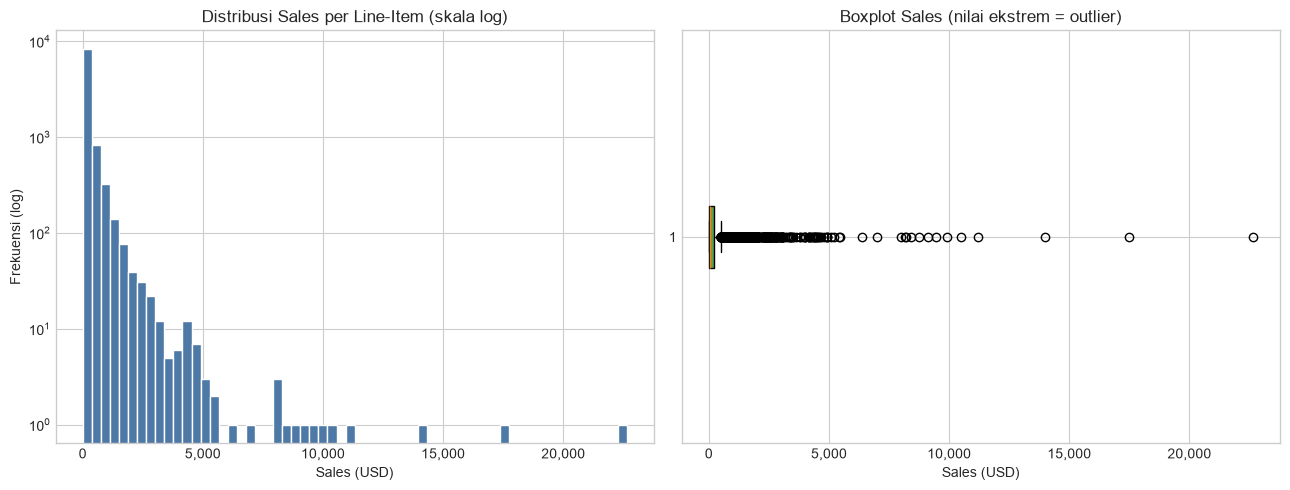

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
ax.hist(df["Sales"], bins=60, color=PALETTE[0], edgecolor="white")
ax.set_yscale("log")
ax.set_title("Distribusi Sales per Line-Item (skala log)")
ax.set_xlabel("Sales (USD)")
ax.set_ylabel("Frekuensi (log)")
ax.xaxis.set_major_formatter(fmt_thousands)

ax = axes[1]
ax.boxplot(df["Sales"], orientation="horizontal", patch_artist=True,
           boxprops=dict(facecolor=PALETTE[2]))
ax.set_title("Boxplot Sales (nilai ekstrem = outlier)")
ax.set_xlabel("Sales (USD)")
ax.xaxis.set_major_formatter(fmt_thousands)

fig.tight_layout()
save_fig(fig, "01_distribusi_sales.png")

### 6.2. Total Sales per Dimensi Kategorikal

[OK] Grafik disimpan -> e:\Project\data-analyst-\eda_output\02_sales_by_dimension.png


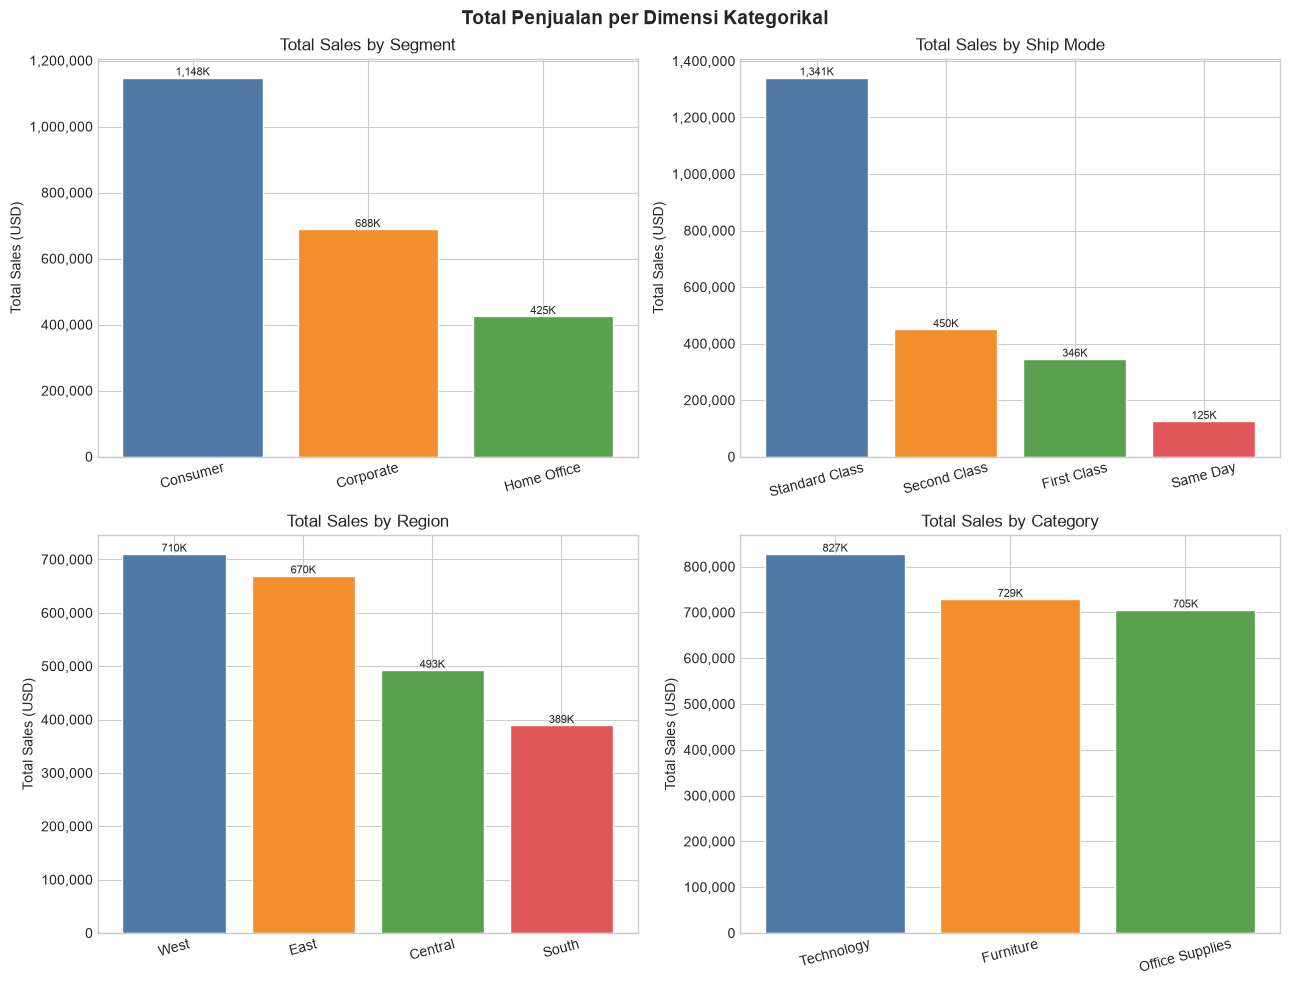

In [8]:
dims = ["Segment", "Ship Mode", "Region", "Category"]
fig, axes = plt.subplots(2, 2, figsize=(13, 10))

for ax, dim in zip(axes.flat, dims):
    agg = (df.groupby(dim)["Sales"].agg(["sum", "count", "mean"])
             .sort_values("sum", ascending=False))
    bars = ax.bar(agg.index.astype(str), agg["sum"],
                  color=PALETTE[:len(agg)], edgecolor="white")
    ax.set_title(f"Total Sales by {dim}")
    ax.set_ylabel("Total Sales (USD)")
    ax.yaxis.set_major_formatter(fmt_thousands)
    ax.tick_params(axis="x", rotation=15)
    for b, v in zip(bars, agg["sum"]):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{v / 1000:,.0f}K",
                ha="center", va="bottom", fontsize=8)

fig.suptitle("Total Penjualan per Dimensi Kategorikal",
             fontsize=14, fontweight="bold")
fig.tight_layout()
save_fig(fig, "02_sales_by_dimension.png")

### 6.3. Total Sales per Sub-Category

[OK] Grafik disimpan -> e:\Project\data-analyst-\eda_output\03_sales_by_subcategory.png


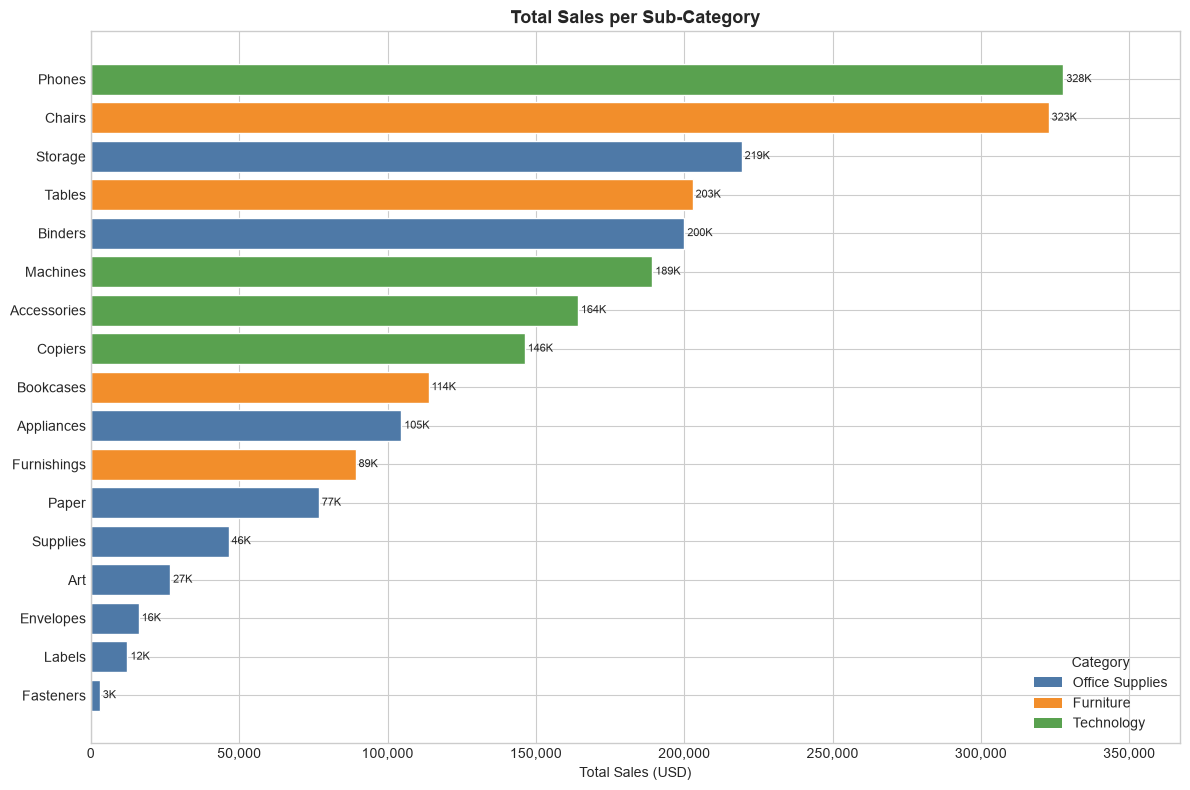

In [9]:
agg = (df.groupby(["Category", "Sub-Category"])["Sales"].sum()
         .sort_values(ascending=True).reset_index())
colors = {cat: PALETTE[i % len(PALETTE)]
          for i, cat in enumerate(agg["Category"].unique())}

fig, ax = plt.subplots(figsize=(12, 8))
ax.barh(agg["Sub-Category"], agg["Sales"],
        color=[colors[c] for c in agg["Category"]], edgecolor="white")
for i, v in enumerate(agg["Sales"]):
    ax.text(v, i, f" {v / 1000:,.0f}K", va="center", fontsize=8)
ax.set_xlim(0, agg["Sales"].max() * 1.12)
ax.set_title("Total Sales per Sub-Category", fontsize=13, fontweight="bold")
ax.set_xlabel("Total Sales (USD)")
ax.xaxis.set_major_formatter(fmt_thousands)
ax.legend(handles=[Patch(facecolor=colors[c], label=c)
                   for c in agg["Category"].unique()],
          title="Category", loc="lower right")
fig.tight_layout()
save_fig(fig, "03_sales_by_subcategory.png")

### 6.4. Geografi: Top 10 State & City

[OK] Grafik disimpan -> e:\Project\data-analyst-\eda_output\04_top_states_cities.png


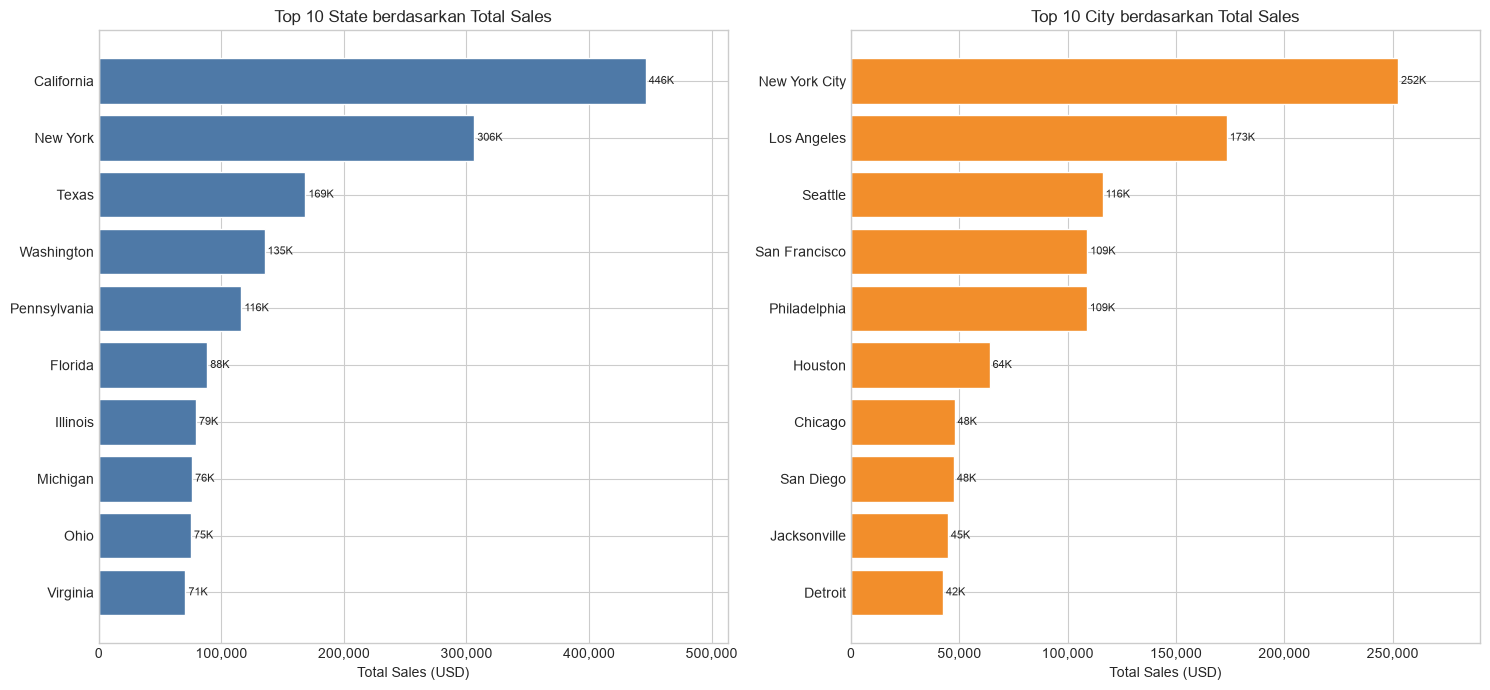

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

top_states = df.groupby("State")["Sales"].sum().nlargest(10).sort_values()
axes[0].barh(top_states.index, top_states.values,
             color=PALETTE[0], edgecolor="white")
for i, v in enumerate(top_states.values):
    axes[0].text(v, i, f" {v / 1000:,.0f}K", va="center", fontsize=8)
axes[0].set_xlim(0, top_states.max() * 1.15)
axes[0].set_title("Top 10 State berdasarkan Total Sales")
axes[0].set_xlabel("Total Sales (USD)")
axes[0].xaxis.set_major_formatter(fmt_thousands)

top_cities = df.groupby("City")["Sales"].sum().nlargest(10).sort_values()
axes[1].barh(top_cities.index, top_cities.values,
             color=PALETTE[1], edgecolor="white")
for i, v in enumerate(top_cities.values):
    axes[1].text(v, i, f" {v / 1000:,.0f}K", va="center", fontsize=8)
axes[1].set_xlim(0, top_cities.max() * 1.15)
axes[1].set_title("Top 10 City berdasarkan Total Sales")
axes[1].set_xlabel("Total Sales (USD)")
axes[1].xaxis.set_major_formatter(fmt_thousands)

fig.tight_layout()
save_fig(fig, "04_top_states_cities.png")

### 6.5. Top 10 Pelanggan & Produk

[OK] Grafik disimpan -> e:\Project\data-analyst-\eda_output\05_top_customers_products.png


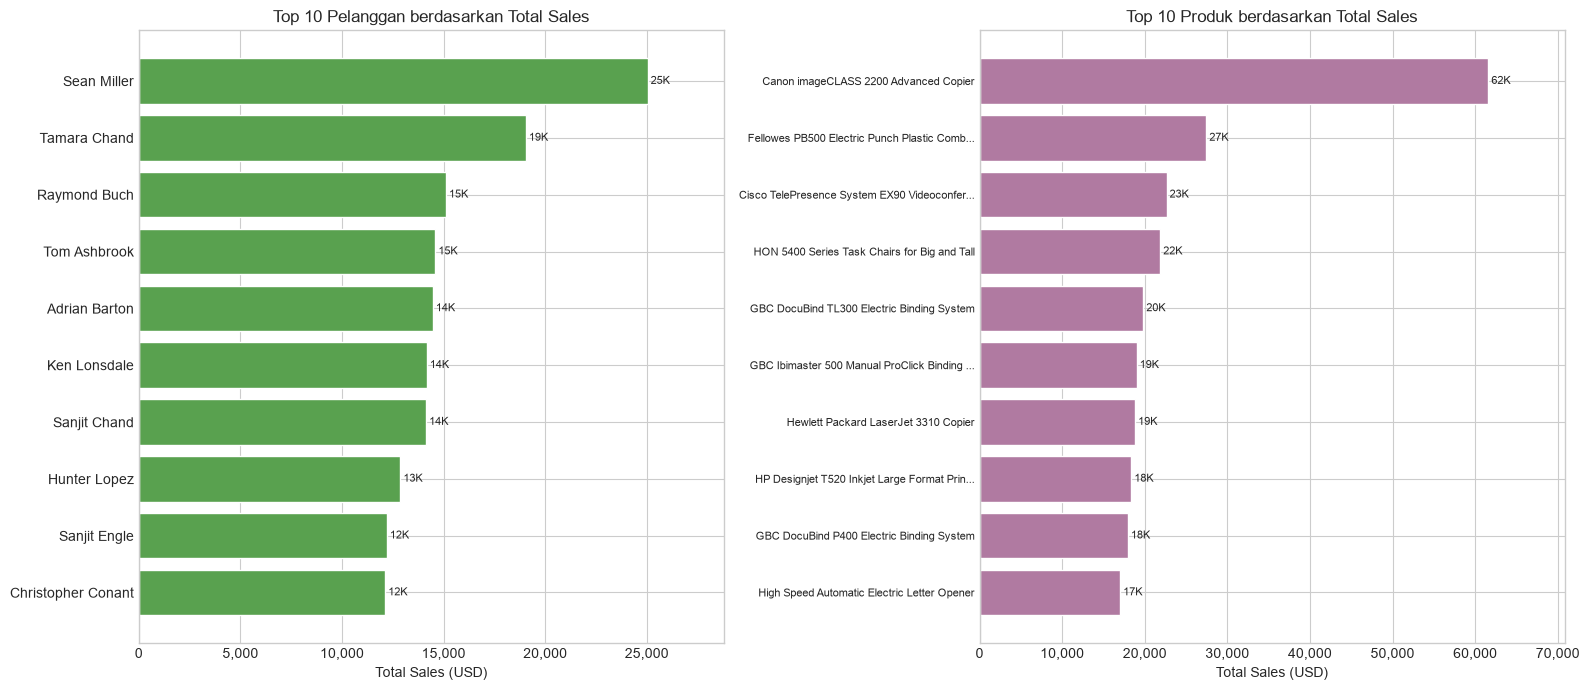

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

top_cust = df.groupby("Customer Name")["Sales"].sum().nlargest(10).sort_values()
axes[0].barh(top_cust.index, top_cust.values,
             color=PALETTE[2], edgecolor="white")
for i, v in enumerate(top_cust.values):
    axes[0].text(v, i, f" {v / 1000:,.0f}K", va="center", fontsize=8)
axes[0].set_xlim(0, top_cust.max() * 1.15)
axes[0].set_title("Top 10 Pelanggan berdasarkan Total Sales")
axes[0].set_xlabel("Total Sales (USD)")
axes[0].xaxis.set_major_formatter(fmt_thousands)

top_prod = df.groupby("Product Name")["Sales"].sum().nlargest(10).sort_values()
labels = [shorten(n) for n in top_prod.index]
axes[1].barh(labels, top_prod.values, color=PALETTE[4], edgecolor="white")
for i, v in enumerate(top_prod.values):
    axes[1].text(v, i, f" {v / 1000:,.0f}K", va="center", fontsize=8)
axes[1].set_xlim(0, top_prod.max() * 1.15)
axes[1].set_title("Top 10 Produk berdasarkan Total Sales")
axes[1].set_xlabel("Total Sales (USD)")
axes[1].xaxis.set_major_formatter(fmt_thousands)
axes[1].tick_params(axis="y", labelsize=8)

fig.tight_layout()
save_fig(fig, "05_top_customers_products.png")

## 7. Analisis Time Series

Tren penjualan bulanan dengan rata-rata bergerak 3 bulan, penjualan tahunan + pertumbuhan YoY, dan ringkasan statistik time series.

[OK] Grafik disimpan -> e:\Project\data-analyst-\eda_output\06_tren_bulanan.png


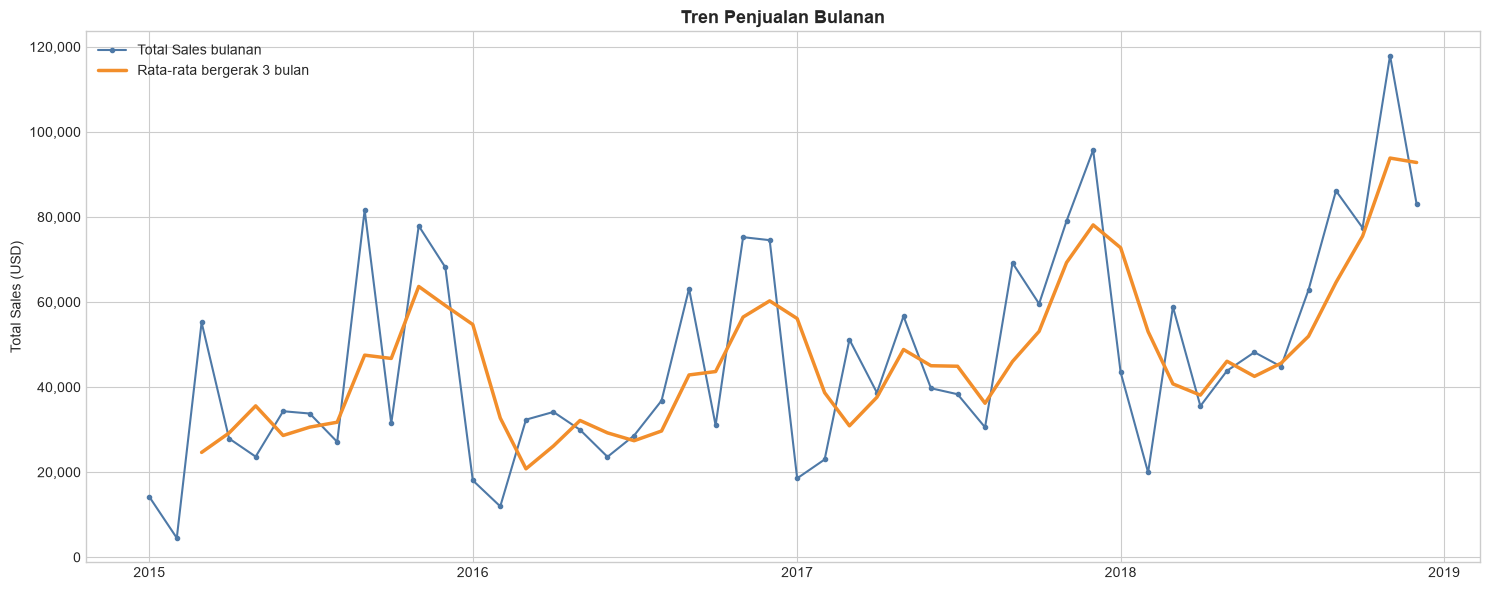

In [12]:
monthly = df.set_index("Order Date").resample("MS")["Sales"].sum()
yearly = df.groupby("Order Year")["Sales"].sum()
growth = yearly.pct_change() * 100

fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(monthly.index, monthly.values, marker="o", ms=3,
        color=PALETTE[0], label="Total Sales bulanan")
ax.plot(monthly.index, monthly.rolling(3).mean(), lw=2.5,
        color=PALETTE[1], label="Rata-rata bergerak 3 bulan")
ax.set_title("Tren Penjualan Bulanan", fontsize=13, fontweight="bold")
ax.set_ylabel("Total Sales (USD)")
ax.yaxis.set_major_formatter(fmt_thousands)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend()
fig.tight_layout()
save_fig(fig, "06_tren_bulanan.png")

[OK] Grafik disimpan -> e:\Project\data-analyst-\eda_output\07_penjualan_tahunan_yoy.png


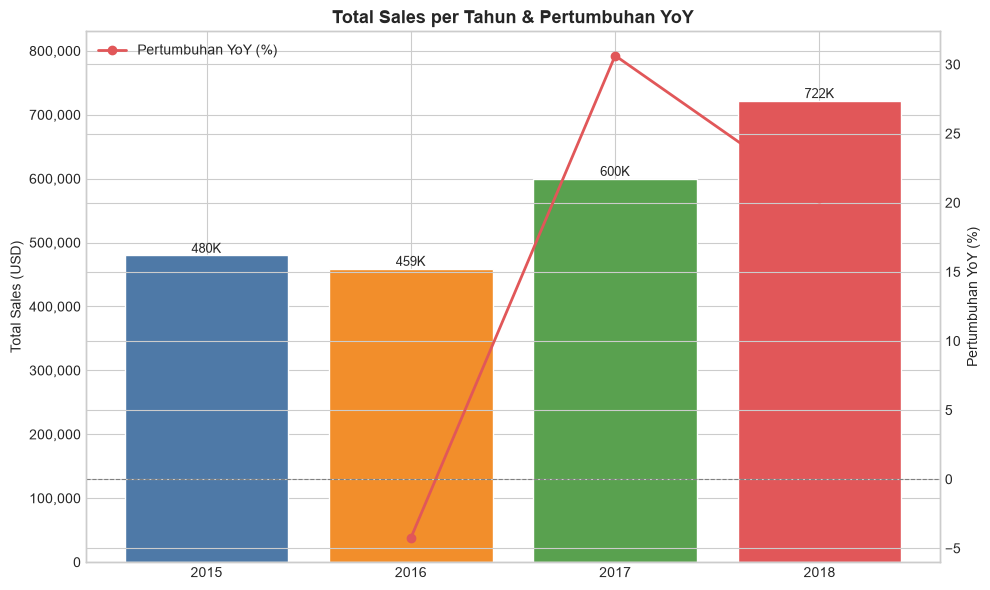

In [13]:
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(yearly.index.astype(str), yearly.values,
              color=PALETTE[:len(yearly)], edgecolor="white")
for b, v in zip(bars, yearly.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v / 1000:,.0f}K",
            ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, yearly.max() * 1.15)
ax.set_title("Total Sales per Tahun & Pertumbuhan YoY",
             fontsize=13, fontweight="bold")
ax.set_ylabel("Total Sales (USD)")
ax.yaxis.set_major_formatter(fmt_thousands)

ax2 = ax.twinx()
g = growth.dropna()
ax2.plot(g.index.astype(str), g.values, marker="o", color=PALETTE[3],
         lw=2, label="Pertumbuhan YoY (%)")
ax2.set_ylabel("Pertumbuhan YoY (%)")
ax2.axhline(0, color="grey", lw=0.8, ls="--")
ax2.legend(loc="upper left")
fig.tight_layout()
save_fig(fig, "07_penjualan_tahunan_yoy.png")

In [14]:
print("Penjualan per tahun:")
for y, v in yearly.items():
    gy = growth.get(y)
    g_txt = "-" if pd.isna(gy) else f"{gy:+.1f}%"
    print(f"  {y} : USD {v:>14,.2f}   (YoY {g_txt})")

peak = monthly.idxmax()
print(f"Bulan tertinggi      : {peak:%b %Y} (USD {monthly.max():,.2f})")
low = monthly.idxmin()
print(f"Bulan terendah       : {low:%b %Y} (USD {monthly.min():,.2f})")
print(f"Rata-rata per bulan  : USD {monthly.mean():,.2f}")

best_q = df.groupby("Order Quarter")["Sales"].sum().idxmax()
print(f"Kuartal terbaik      : {best_q} "
      f"(USD {df.groupby('Order Quarter')['Sales'].sum().max():,.2f})")

Penjualan per tahun:
  2015 : USD     479,856.21   (YoY -)
  2016 : USD     459,436.01   (YoY -4.3%)
  2017 : USD     600,192.55   (YoY +30.6%)
  2018 : USD     722,052.02   (YoY +20.3%)
Bulan tertinggi      : Nov 2018 (USD 117,938.15)
Bulan terendah       : Feb 2015 (USD 4,519.89)
Rata-rata per bulan  : USD 47,115.35
Kuartal terbaik      : 2018Q4 (USD 278,416.67)


### 7.1. Heatmap Penjualan: Bulan × Tahun

[OK] Grafik disimpan -> e:\Project\data-analyst-\eda_output\08_heatmap_bulan_tahun.png


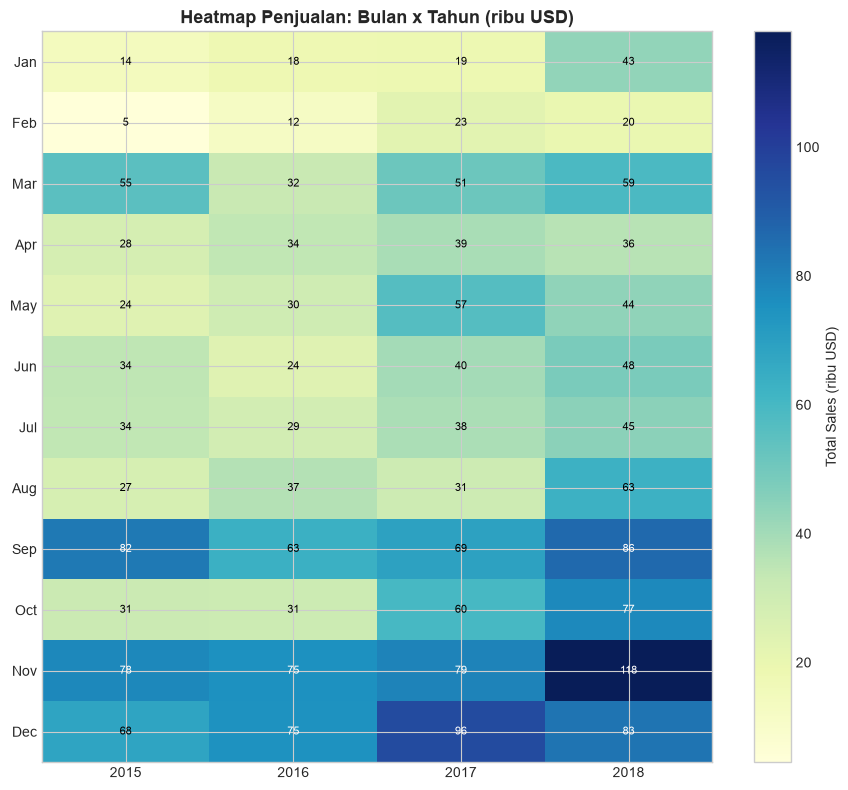

In [15]:
pivot = df.pivot_table(index="Order Month", columns="Order Year",
                       values="Sales", aggfunc="sum").sort_index()
data = pivot.values / 1000.0  # dalam ribuan USD

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(data, cmap="YlGnBu", aspect="auto")
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels([str(c) for c in pivot.columns])
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(MONTH_NAMES)
for i in range(data.shape[0]):
    for j in range(data.shape[1]):
        val = data[i, j]
        if np.isfinite(val):
            ax.text(j, i, f"{val:,.0f}", ha="center", va="center",
                    fontsize=8,
                    color="white" if val > data.max() * 0.6 else "black")
fig.colorbar(im, ax=ax, label="Total Sales (ribu USD)")
ax.set_title("Heatmap Penjualan: Bulan x Tahun (ribu USD)",
             fontsize=13, fontweight="bold")
fig.tight_layout()
save_fig(fig, "08_heatmap_bulan_tahun.png")

## 8. Analisis Pengiriman

Distribusi lama pengiriman dan rata-rata nilai transaksi per `Ship Mode`.

In [16]:
summary = df.groupby("Ship Mode").agg(
    transaksi=("Order ID", "count"),
    total_sales=("Sales", "sum"),
    rata_sales=("Sales", "mean"),
    rata_hari_kirim=("Shipping Days", "mean"),
).round(2)
summary

,transaksi,total_sales,rata_sales,rata_hari_kirim
Ship Mode,,,,
First Class,1501,345572.26,230.23,2.18
Same Day,538,125219.04,232.75,0.04
Second Class,1902,449914.18,236.55,3.25
Standard Class,5859,1340831.31,228.85,5.01


[OK] Grafik disimpan -> e:\Project\data-analyst-\eda_output\09_pengiriman.png


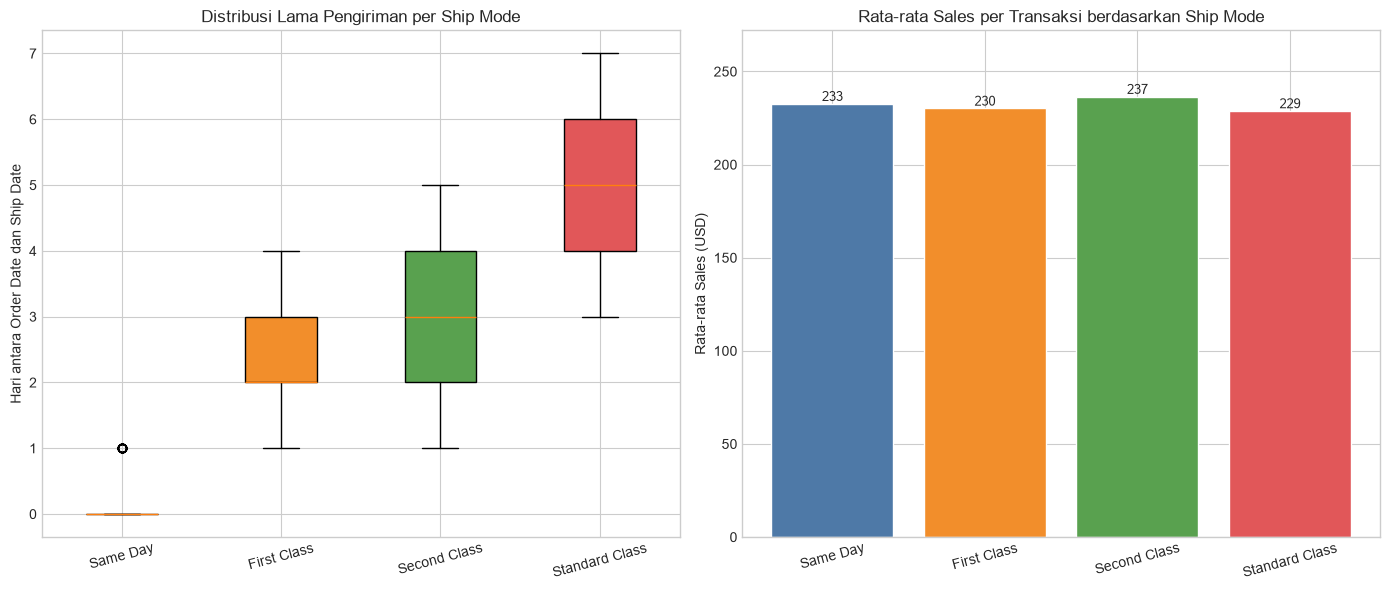

In [17]:
order = [m for m in ["Same Day", "First Class", "Second Class",
                     "Standard Class"] if m in set(df["Ship Mode"])]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

data = [df.loc[df["Ship Mode"] == m, "Shipping Days"].values for m in order]
bp = axes[0].boxplot(data, patch_artist=True)
for patch, color in zip(bp["boxes"], PALETTE):
    patch.set_facecolor(color)
axes[0].set_xticks(range(1, len(order) + 1))
axes[0].set_xticklabels(order, rotation=15)
axes[0].set_title("Distribusi Lama Pengiriman per Ship Mode")
axes[0].set_ylabel("Hari antara Order Date dan Ship Date")

avg = df.groupby("Ship Mode")["Sales"].mean().reindex(order)
bars = axes[1].bar(order, avg.values, color=PALETTE[:len(order)],
                   edgecolor="white")
for b, v in zip(bars, avg.values):
    axes[1].text(b.get_x() + b.get_width() / 2, v, f"{v:,.0f}",
                 ha="center", va="bottom", fontsize=9)
axes[1].set_ylim(0, avg.max() * 1.15)
axes[1].set_title("Rata-rata Sales per Transaksi berdasarkan Ship Mode")
axes[1].set_ylabel("Rata-rata Sales (USD)")
axes[1].tick_params(axis="x", rotation=15)

fig.tight_layout()
save_fig(fig, "09_pengiriman.png")

## 9. Pelanggan & Produk

Konsentrasi pelanggan (top-10), median sales per pelanggan, dan produk terlaris.

In [18]:
cust = df.groupby("Customer Name").agg(
    total_sales=("Sales", "sum"),
    jumlah_transaksi=("Order ID", "count"),
)
share = cust["total_sales"].nlargest(10).sum() / cust["total_sales"].sum() * 100

print(f"Jumlah pelanggan                : {len(cust):,}")
print(f"Kontribusi Top-10 pelanggan     : {share:.1f}% dari total sales")
print(f"Median sales per pelanggan      : USD {cust['total_sales'].median():,.2f}")
print()
print("Top 5 pelanggan:")
for name, row in cust.nlargest(5, "total_sales").iterrows():
    print(f"  - {name:<25} USD {row['total_sales']:>12,.2f} "
          f"({int(row['jumlah_transaksi'])} transaksi)")

prod = df.groupby("Product Name")["Sales"].agg(["sum", "count"])
print()
print("Top 5 produk:")
for name, row in prod.nlargest(5, "sum").iterrows():
    print(f"  - {shorten(name, 55):<55} USD {row['sum']:>12,.2f} "
          f"({int(row['count'])}x terjual)")

Jumlah pelanggan                : 793
Kontribusi Top-10 pelanggan     : 6.8% dari total sales
Median sales per pelanggan      : USD 2,215.00

Top 5 pelanggan:
  - Sean Miller               USD    25,043.05 (15 transaksi)
  - Tamara Chand              USD    19,052.22 (12 transaksi)
  - Raymond Buch              USD    15,117.34 (18 transaksi)
  - Tom Ashbrook              USD    14,595.62 (10 transaksi)
  - Adrian Barton             USD    14,473.57 (20 transaksi)

Top 5 produk:
  - Canon imageCLASS 2200 Advanced Copier                   USD    61,599.82 (5x terjual)
  - Fellowes PB500 Electric Punch Plastic Comb Binding M... USD    27,453.38 (10x terjual)
  - Cisco TelePresence System EX90 Videoconferencing Unit   USD    22,638.48 (1x terjual)
  - HON 5400 Series Task Chairs for Big and Tall            USD    21,870.58 (8x terjual)
  - GBC DocuBind TL300 Electric Binding System              USD    19,823.48 (11x terjual)


## 10. Simpan Tabel Agregat

Tabel agregat (format CSV) disimpan ke folder `eda_output/` — sama seperti versi skrip.

In [19]:
os.makedirs(OUTPUT_DIR, exist_ok=True)

monthly = df.set_index("Order Date").resample("MS")["Sales"].sum().round(2)
tables = {
    "agg_sales_by_category.csv": (
        df.groupby(["Category", "Sub-Category"])["Sales"]
          .agg(["sum", "count", "mean"]).round(2)),
    "agg_sales_by_region.csv": (
        df.groupby(["Region", "State"])["Sales"]
          .agg(["sum", "count", "mean"]).round(2)),
    "agg_monthly_sales.csv": monthly,
    "agg_yearly_sales.csv": (
        df.groupby("Order Year")["Sales"].sum().round(2)),
    "agg_top_customers.csv": (
        df.groupby("Customer Name")["Sales"]
          .agg(["sum", "count"]).nlargest(50, "sum").round(2)),
    "agg_top_products.csv": (
        df.groupby("Product Name")["Sales"]
          .agg(["sum", "count"]).nlargest(50, "sum").round(2)),
}
for name, table in tables.items():
    path = os.path.join(OUTPUT_DIR, name)
    table.to_csv(path)
    print(f"[OK] Tabel disimpan -> {path}")

[OK] Tabel disimpan -> e:\Project\data-analyst-\eda_output\agg_sales_by_category.csv
[OK] Tabel disimpan -> e:\Project\data-analyst-\eda_output\agg_sales_by_region.csv
[OK] Tabel disimpan -> e:\Project\data-analyst-\eda_output\agg_monthly_sales.csv
[OK] Tabel disimpan -> e:\Project\data-analyst-\eda_output\agg_yearly_sales.csv
[OK] Tabel disimpan -> e:\Project\data-analyst-\eda_output\agg_top_customers.csv
[OK] Tabel disimpan -> e:\Project\data-analyst-\eda_output\agg_top_products.csv


## 11. Kesimpulan & Insight Utama

In [20]:
yearly = df.groupby("Order Year")["Sales"].sum()
growth = yearly.pct_change().iloc[-1] * 100
monthly = df.set_index("Order Date").resample("MS")["Sales"].sum()
peak = monthly.idxmax()
cust = df.groupby("Customer Name")["Sales"].sum()
share = cust.nlargest(10).sum() / cust.sum() * 100
city_state = df.groupby(["State", "City"])["Sales"].sum().idxmax()

print(f"- Kategori terlaris          : {df.groupby('Category')['Sales'].sum().idxmax()}")
print(f"- Sub-kategori terlaris      : {df.groupby('Sub-Category')['Sales'].sum().idxmax()}")
print(f"- Region dengan sales terbesar: {df.groupby('Region')['Sales'].sum().idxmax()}")
print(f"- State dengan sales terbesar : {df.groupby('State')['Sales'].sum().idxmax()}")
print(f"- Kota dengan sales terbesar  : {city_state[1]} ({city_state[0]})")
print(f"- Pertumbuhan tahun terakhir  : {growth:+.1f}% "
      f"({yearly.index[-2]} -> {yearly.index[-1]})")
print(f"- Puncak musiman             : {peak:%B %Y} "
      f"(USD {monthly.max():,.2f})")
print(f"- Konsentrasi pelanggan      : Top-10 pelanggan menyumbang "
      f"{share:.1f}% total sales")
print("- Distribusi Sales           : sangat right-skewed, mayoritas "
      "transaksi bernilai kecil dengan sejumlah outlier besar")
print("  (median jauh di bawah mean - lihat grafik 01)")

- Kategori terlaris          : Technology
- Sub-kategori terlaris      : Phones
- Region dengan sales terbesar: West
- State dengan sales terbesar : California
- Kota dengan sales terbesar  : New York City (New York)
- Pertumbuhan tahun terakhir  : +20.3% (2017 -> 2018)
- Puncak musiman             : November 2018 (USD 117,938.15)
- Konsentrasi pelanggan      : Top-10 pelanggan menyumbang 6.8% total sales
- Distribusi Sales           : sangat right-skewed, mayoritas transaksi bernilai kecil dengan sejumlah outlier besar
  (median jauh di bawah mean - lihat grafik 01)
